# Portfolio Risk Analysis with MF-DCCA — Real Tickers, VaR's Axiom Failures, and Extensions

Runs on your **actual universe** from `dfa_and_its_variants.ipynb` (same `TICKERS`,
same `stock_csv_data/` CSVs / auto-download fallback) — no synthetic data.

**Structure**
1. Coherent risk-measure axioms (monotonicity, sub-additivity, homogeneity, translation invariance)
2. MF-DFA / MF-DCCA core functions
3. Load real prices for a sector-diversified sub-portfolio
4. Single-asset & cross-asset (MF-DCCA) multifractal spectra
5. Portfolio-level MF-DFA — actual vs. naively-aggregated scaling (returns)
6. **[New]** Component vs. portfolio volatility character — is anyone's clustering/persistence retained?
7. **[New]** Multifractal Diversification Ratio — a spectral-width analogue of the classic diversification ratio
8. **[New]** Rolling MF-DCCA — time-varying cross-correlation as an early-warning signal
9. VaR vs. the √T homogeneous-scaling assumption
10. **[New]** Asymmetric MF-DFA — up-move vs. down-move persistence (leverage-effect / tail-asymmetry diagnostic)
11. **[New]** Multifractal-aware Expected Shortfall — Hill/EVT tail index cross-checked against MF-DFA spectral width
12. Sub-additivity counterexample (VaR vs. ES)
13. Takeaways


## 1. Coherent risk measures — the four axioms

A risk measure $\rho$ mapping a loss distribution to a capital number is **coherent**
(Artzner–Delbaen–Eber–Heath, 1999) if it satisfies:

**1. Monotonicity** — $X \le Y$ always $\Rightarrow \rho(X) \le \rho(Y)$. Riskier positions get a riskier number.

**2. Sub-additivity** — $\rho(X+Y) \le \rho(X)+\rho(Y)$. Merging/diversifying can never *create* risk.
**VaR can violate this** — that alone is why VaR is not coherent.

**3. Positive homogeneity** — $\rho(\lambda X) = \lambda\,\rho(X)$ for $\lambda \ge 0$. Risk scales
linearly with size. VaR satisfies this for a *fixed distribution shape and horizon* — but the
practical shortcut used to move VaR across **horizons** (the $\sqrt{T}$ rule) additionally assumes
the process is self-similar with Hurst exponent exactly 0.5 at every quantile, i.e. *monofractal*.
MF-DFA's $h(q)$ curve tests that assumption directly.

**4. Translation invariance** — $\rho(X+c) = \rho(X) - c$. Adding sure cash $c$ reduces required
capital by exactly $c$. VaR satisfies this; not where multifractality matters.

$$\mathrm{VaR}_\alpha(X) = \inf\{x : P(X > x) \le 1-\alpha\}$$

is a quantile — monotone and translation-invariant by construction, but sub-additivity and the
implicit scaling assumption behind Axiom 3's horizon extension are both testable empirically, and
both are exactly what MF-DFA / MF-DCCA are built to test.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import os
matplotlib.rcParams["figure.dpi"] = 110

# ------------------------------------------------------------------
# MF-DFA / MF-DCCA core
# ------------------------------------------------------------------
def profile(x):
    return np.cumsum(np.asarray(x) - np.mean(x))

def _local_residuals(Y, s, order=1, sign_filter=None):
    '''F2 per non-overlapping window (both directions). sign_filter in {None,"+","-"}
    keeps only windows whose local linear trend slope has that sign (asymmetric MF-DFA).'''
    N = len(Y); Ns = N // s; t = np.arange(s)
    out = []
    for v in range(Ns):
        seg = Y[v*s:(v+1)*s]
        c = np.polyfit(t, seg, order)
        if sign_filter == "+" and c[-2] < 0: continue
        if sign_filter == "-" and c[-2] >= 0: continue
        out.append(np.mean((seg - np.polyval(c, t)) ** 2))
    for v in range(Ns):
        seg = Y[N-(v+1)*s:N-v*s]
        c = np.polyfit(t, seg, order)
        if sign_filter == "+" and c[-2] < 0: continue
        if sign_filter == "-" and c[-2] >= 0: continue
        out.append(np.mean((seg - np.polyval(c, t)) ** 2))
    return np.array(out)

def mfdfa(x, q_list, scales, order=1, sign_filter=None):
    Y = profile(x)
    q_list = np.asarray(q_list, dtype=float)
    Fq = np.zeros((len(q_list), len(scales)))
    for si, s in enumerate(scales):
        F2 = _local_residuals(Y, s, order, sign_filter)
        F2 = F2[F2 > 1e-14]
        for qi, q in enumerate(q_list):
            if abs(q) < 1e-8:
                Fq[qi, si] = np.exp(0.5*np.mean(np.log(F2)))
            else:
                Fq[qi, si] = np.mean(F2**(q/2.0))**(1.0/q)
    hq = np.array([np.polyfit(np.log(scales), np.log(Fq[qi]), 1)[0]
                    for qi in range(len(q_list))])
    return Fq, hq

def multifractal_spectrum(q_list, hq):
    q = np.asarray(q_list, dtype=float)
    tau = q*hq - 1
    alpha = np.gradient(tau, q)
    f = q*alpha - tau
    return tau, alpha, f

def dcca_rho(x, y, s, order=1):
    X, Y2 = profile(x), profile(y)
    N = len(X); Ns = N // s; t = np.arange(s)
    Fxx = Fyy = Fxy = 0.0
    for v in range(Ns):
        xs, ys = X[v*s:(v+1)*s], Y2[v*s:(v+1)*s]
        cx = np.polyval(np.polyfit(t, xs, order), t)
        cy = np.polyval(np.polyfit(t, ys, order), t)
        rx, ry = xs-cx, ys-cy
        Fxx += np.mean(rx**2); Fyy += np.mean(ry**2); Fxy += np.mean(rx*ry)
    Fxx, Fyy, Fxy = Fxx/Ns, Fyy/Ns, Fxy/Ns
    return Fxy / np.sqrt(Fxx*Fyy)

def mf_dcca_hxy(x, y, q_list, scales, order=1):
    X, Y2 = profile(x), profile(y)
    q_list = np.asarray(q_list, dtype=float)
    Fxy_q = np.zeros((len(q_list), len(scales)))
    for si, s in enumerate(scales):
        N = len(X); Ns = N // s; t = np.arange(s)
        Fxy = np.empty(2*Ns)
        for v in range(Ns):
            xs, ys = X[v*s:(v+1)*s], Y2[v*s:(v+1)*s]
            cx = np.polyval(np.polyfit(t, xs, order), t)
            cy = np.polyval(np.polyfit(t, ys, order), t)
            Fxy[v] = np.mean((xs-cx)*(ys-cy))
        for v in range(Ns):
            xs = X[N-(v+1)*s:N-v*s]; ys = Y2[N-(v+1)*s:N-v*s]
            cx = np.polyval(np.polyfit(t, xs, order), t)
            cy = np.polyval(np.polyfit(t, ys, order), t)
            Fxy[Ns+v] = np.mean((xs-cx)*(ys-cy))
        Fxy = np.abs(Fxy); Fxy = Fxy[Fxy > 1e-14]
        for qi, q in enumerate(q_list):
            Fxy_q[qi, si] = np.mean(Fxy**(q/2.0))**(1.0/q) if abs(q) > 1e-8 \
                             else np.exp(0.5*np.mean(np.log(Fxy)))
    return np.array([np.polyfit(np.log(scales), np.log(Fxy_q[qi]), 1)[0]
                      for qi in range(len(q_list))])

# ------------------------------------------------------------------
# NEW: Hill tail-index estimator (standard EVT, used in Section 10)
# ------------------------------------------------------------------
def hill_estimator(losses, k):
    '''Hill estimator of the tail index alpha from the k largest losses (upper tail).
    Smaller alpha = fatter tail. Returns alpha (not xi=1/alpha).'''
    x = np.sort(losses)[::-1][:k+1]
    logs = np.log(x[:-1] / x[-1])
    return k / np.sum(logs)

print("Core MF-DFA / MF-DCCA / Hill functions loaded.")


Core MF-DFA / MF-DCCA / Hill functions loaded.


## 2. Loading real data — same universe as `dfa_and_its_variants.ipynb`

Uses the exact same `TICKERS` list / `stock_csv_data/<TICKER>_data.csv` convention as your
download cell — if a CSV is already there it's reused, otherwise it's fetched with `yfinance`
(no synthetic data). A sector-diverse 7-name sub-portfolio is picked for tractable pairwise
MF-DCCA (21 pairs); swap `PORTFOLIO` for any subset of `TICKERS` you like — the rest of the
notebook doesn't change.


In [2]:
TICKERS = [
    # US Large Cap Tech
    "AAPL", "MSFT", "GOOG", "AMZN", "NVDA",
    "META", "TSLA", "NFLX", "AMD", "INTC",
    # US Financials
    "JPM", "BAC", "GS", "MS", "WFC",
    "BLK", "C", "AXP", "V", "MA",
    # US Healthcare & Consumer
    "JNJ", "PFE", "UNH", "MRK", "ABBV",
    "PG", "KO", "PEP", "WMT", "COST",
    # US Energy & Industrials
    "XOM", "CVX", "COP", "BA", "CAT",
    "GE", "HON", "LMT", "RTX", "UPS",
    # Commodities & Crypto
    "GC=F", "SI=F", "CL=F", "BTC-USD", "ETH-USD",
    # International ETFs
    "EWJ", "EWZ", "FXI", "EWG", "EWU",
]

START, END = "2010-01-01", "2026-04-11"
OUT_DIR = "stock_csv_data"
os.makedirs(OUT_DIR, exist_ok=True)

# Sector-diverse sub-portfolio for the pairwise MF-DCCA analysis below.
PORTFOLIO = ["AAPL", "JPM", "XOM", "JNJ", "GC=F", "BTC-USD", "EWJ"]
SECTOR    = {"AAPL":"Tech", "JPM":"Financials", "XOM":"Energy", "JNJ":"Healthcare",
             "GC=F":"Commodity", "BTC-USD":"Crypto", "EWJ":"Intl ETF"}

def csv_path(ticker, folder=OUT_DIR):
    return os.path.join(folder, f"{ticker.replace('=', '_')}_data.csv")

def get_prices(tickers, start=START, end=END, folder=OUT_DIR):
    '''Reuse existing CSVs from your dfa_and_its_variants.ipynb download step;
    fetch any missing ones the same way that notebook does.'''
    series = {}
    for t in tickers:
        path = csv_path(t, folder)
        if not os.path.exists(path):
            import yfinance as yf
            print(f"Downloading {t} ...")
            data = yf.download(t, start=start, end=end, progress=False)
            if isinstance(data.columns, pd.MultiIndex):
                data.columns = data.columns.get_level_values(0)
            data.to_csv(path)
        df = pd.read_csv(path)
        df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
        df = df.dropna(subset=["Date"]).set_index("Date")
        series[t] = pd.to_numeric(df["Close"], errors="coerce")
    price_df = pd.DataFrame(series).dropna()
    return price_df

price_df = get_prices(PORTFOLIO)
returns  = {t: np.diff(np.log(price_df[t].values)) for t in PORTFOLIO}
dates    = price_df.index[1:]
N        = len(dates)
print(f"{len(PORTFOLIO)} assets, {N} aligned daily log-returns "
      f"({dates[0].date()} -> {dates[-1].date()}, ~{N/252:.1f} yrs)")
price_df.tail()


7 assets, 2904 aligned daily log-returns (2014-09-18 -> 2026-04-10, ~11.5 yrs)


,AAPL,JPM,XOM,JNJ,GC=F,BTC-USD,EWJ
Date,,,,,,,
2026-04-06,258.398865,294.125000,161.224655,239.592087,4656.799805,68859.828125,85.107582
2026-04-07,253.048416,296.066254,161.757568,237.046738,4657.100098,71940.703125,85.047913
2026-04-08,258.438812,306.588837,154.168549,239.920212,4749.500000,71123.359375,88.926834
2026-04-09,260.025970,308.938232,153.004044,239.930145,4792.200195,71767.828125,87.743263
2026-04-10,260.015991,308.480316,150.507248,237.096451,4761.899902,72979.046875,87.653748


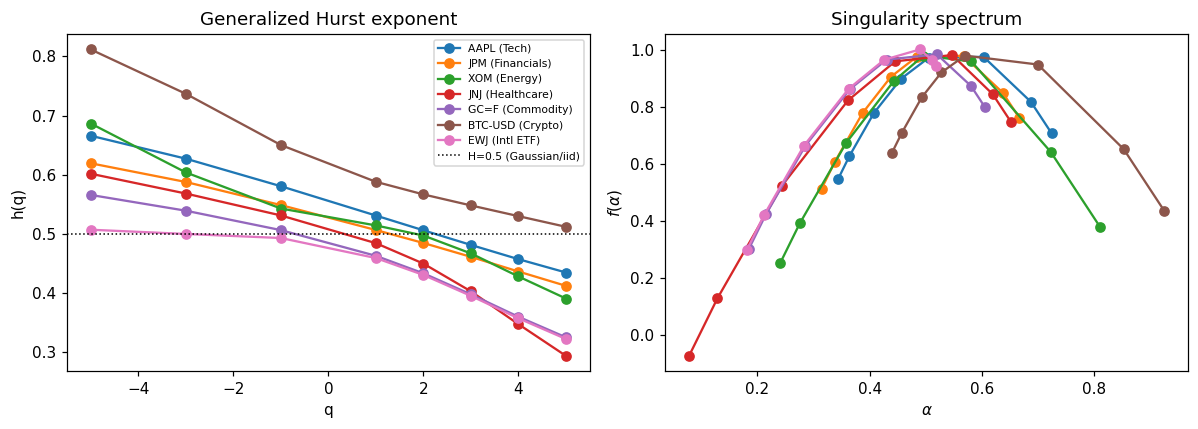

AAPL      (Tech      )  h(2)=0.506   width Δh=0.232
JPM       (Financials)  h(2)=0.484   width Δh=0.208
XOM       (Energy    )  h(2)=0.497   width Δh=0.296
JNJ       (Healthcare)  h(2)=0.449   width Δh=0.308
GC=F      (Commodity )  h(2)=0.433   width Δh=0.241
BTC-USD   (Crypto    )  h(2)=0.566   width Δh=0.300
EWJ       (Intl ETF  )  h(2)=0.430   width Δh=0.185


In [3]:
q_list = np.array([-5,-3,-1,1,2,3,4,5], dtype=float)
scales = np.unique(np.geomspace(16, N//8, 16).astype(int))

spectra = {}
for name, r in returns.items():
    Fq, hq = mfdfa(r, q_list, scales)
    tau, alpha, f = multifractal_spectrum(q_list, hq)
    spectra[name] = dict(hq=hq, tau=tau, alpha=alpha, f=f, width=hq[0]-hq[-1])

fig, ax = plt.subplots(1, 2, figsize=(11,4))
for name in PORTFOLIO:
    ax[0].plot(q_list, spectra[name]["hq"], "o-", label=f"{name} ({SECTOR[name]})")
    ax[1].plot(spectra[name]["alpha"], spectra[name]["f"], "o-", label=name)
ax[0].axhline(0.5, color="k", ls=":", lw=1, label="H=0.5 (Gaussian/iid)")
ax[0].set_xlabel("q"); ax[0].set_ylabel("h(q)"); ax[0].set_title("Generalized Hurst exponent")
ax[0].legend(fontsize=7)
ax[1].set_xlabel(r"$\alpha$"); ax[1].set_ylabel(r"$f(\alpha)$")
ax[1].set_title("Singularity spectrum")
plt.tight_layout(); plt.show()

for name in PORTFOLIO:
    s = spectra[name]
    print(f"{name:9s} ({SECTOR[name]:10s})  h(2)={s['hq'][q_list==2][0]:.3f}   width Δh={s['width']:.3f}")


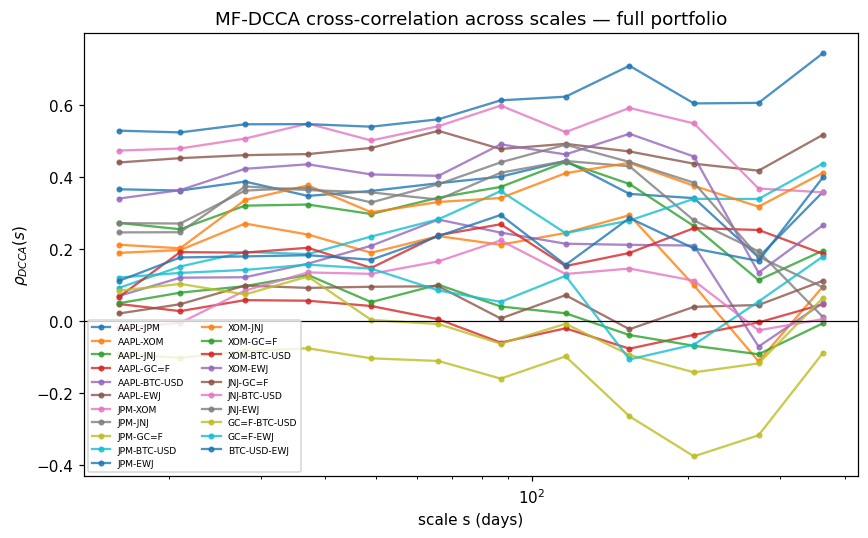

In [4]:
s_fixed = np.unique(np.geomspace(16, N//8, 12).astype(int))
pairs = [(PORTFOLIO[i], PORTFOLIO[j]) for i in range(len(PORTFOLIO))
                                        for j in range(i+1, len(PORTFOLIO))]

fig, ax = plt.subplots(figsize=(8,5))
for a, b in pairs:
    rho_s = [dcca_rho(returns[a], returns[b], s) for s in s_fixed]
    ax.plot(s_fixed, rho_s, "o-", label=f"{a}-{b}", alpha=0.8, ms=3)
ax.axhline(0, color="k", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("scale s (days)"); ax.set_ylabel(r"$\rho_{DCCA}(s)$")
ax.set_title("MF-DCCA cross-correlation across scales — full portfolio")
ax.legend(fontsize=6, ncol=2); plt.tight_layout(); plt.show()


**Why MF-DCCA, not just a correlation matrix:** ordinary correlation assumes co-movement
is the same at every horizon. `ρ_DCCA(s)` shows whether pairs that look uncorrelated day-to-day
(useful diversifiers on paper) become coupled at the horizon that matters for a 10–21 day VaR —
exactly where a 1-day correlation matrix would mislead a risk model.


## 3. Portfolio-level MF-DFA: risk doesn't add up linearly

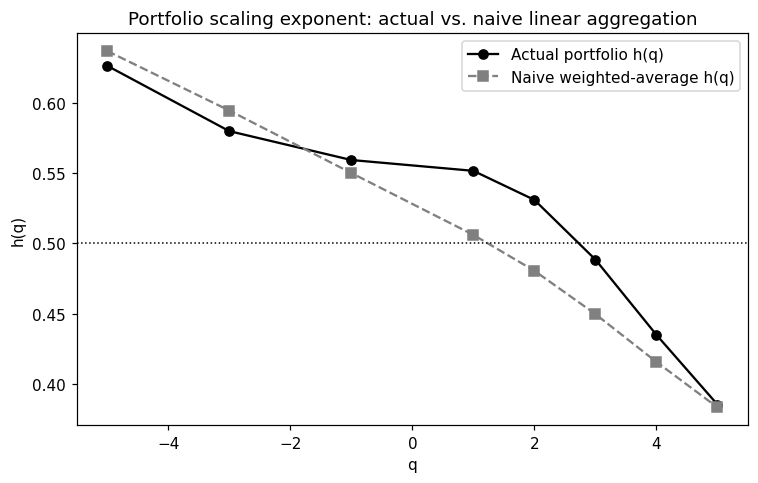

h(2): actual=0.531  naive=0.481
width Δh: actual=0.240  naive weighted-avg=0.253


In [5]:
weights = np.ones(len(PORTFOLIO)) / len(PORTFOLIO)
port_ret = sum(w*returns[n] for w, n in zip(weights, PORTFOLIO))

Fq_p, hq_p = mfdfa(port_ret, q_list, scales)
tau_p, alpha_p, f_p = multifractal_spectrum(q_list, hq_p)
width_p = hq_p[0] - hq_p[-1]
naive_hq = sum(w*spectra[n]["hq"] for w, n in zip(weights, PORTFOLIO))
naive_width = sum(w*spectra[n]["width"] for w, n in zip(weights, PORTFOLIO))

fig, ax = plt.subplots(figsize=(7,4.5))
ax.plot(q_list, hq_p, "o-", color="black", label="Actual portfolio h(q)")
ax.plot(q_list, naive_hq, "s--", color="gray", label="Naive weighted-average h(q)")
ax.axhline(0.5, color="k", ls=":", lw=1)
ax.set_xlabel("q"); ax.set_ylabel("h(q)")
ax.set_title("Portfolio scaling exponent: actual vs. naive linear aggregation")
ax.legend(); plt.tight_layout(); plt.show()

print(f"h(2): actual={hq_p[q_list==2][0]:.3f}  naive={naive_hq[q_list==2][0]:.3f}")
print(f"width Δh: actual={width_p:.3f}  naive weighted-avg={naive_width:.3f}")


## 4. [New] Component vs. Portfolio: Is Any Volatility Character Retained?

Section 3 looked at the *return* series' scaling exponent. Volatility is a different, and in
some ways more diagnostic, lens: individual assets are well known to have long-memory,
multifractal **volatility** (clustering) even when their raw returns are close to white noise
(Ding, Granger & Engle, 1993). The question here: when several such assets are combined into a
portfolio, whose volatility "signature" survives — does the portfolio inherit one dominant
component's clustering behavior, does it average out into something blander (diversification
working as intended), or does it develop a *distinct* character that isn't a simple blend of
any component's?

We build two portfolio-level volatility proxies to separate these effects:

- $v_p(t) = |r_p(t)|$ — volatility of the **actual, netted** portfolio return. Idiosyncratic
  moves can cancel here; this is "what a risk manager actually observes."
- $v_p^{naive}(t) = \sum_i w_i\,|r_i(t)|$ — the **weighted average of component volatilities**,
  with no netting at all. This is the volatility character you'd get from a portfolio of
  perfectly co-moving (never-cancelling) legs — an upper-bound benchmark, not a real position.

Comparing MF-DFA on $v_p$ vs $v_p^{naive}$ isolates how much of "the portfolio's volatility
character" is actually diversification at work, versus simple superposition.


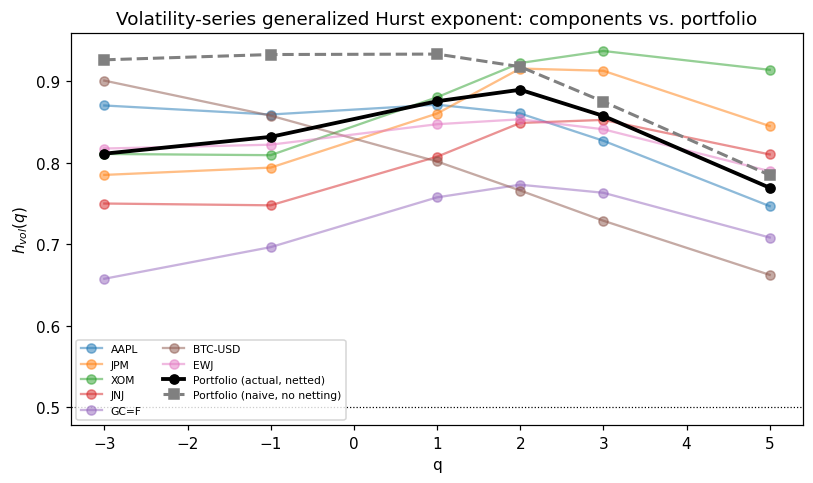

Series                  h_vol(2)   width Δh_vol
AAPL                    0.860      0.123
JPM                     0.915      -0.060
XOM                     0.922      -0.103
JNJ                     0.849      -0.060
GC=F                    0.773      -0.051
BTC-USD                 0.766      0.238
EWJ                     0.853      0.028
Portfolio (actual)      0.889      0.042
Portfolio (naive)       0.918      0.141

Volatility Diversification Ratio (unsigned, |Δh_vol| naive-avg / |Δh_vol| actual) = 2.266
  > 1  -> netting genuinely shrinks typical multifractal scale-heterogeneity (real diversification)
  ~ 1  -> portfolio volatility looks like a simple superposition of components
  < 1  -> netting makes volatility MORE scale-heterogeneous (rare; check for a dominant,
          weakly-hedged component driving the mix)

[diagnostic] signed-width version = 0.395 -- if this disagrees sharply with the
  unsigned version above, some components have opposite-signed Δh_vol (large-vol episode

In [6]:
vol = {name: np.abs(r) for name, r in returns.items()}
vol_p       = np.abs(port_ret)
vol_p_naive = sum(w*vol[n] for w, n in zip(weights, PORTFOLIO))

vscales = np.unique(np.geomspace(16, N//8, 14).astype(int))
vq_list = np.array([-3,-1,1,2,3,5], dtype=float)

vol_spectra = {}
for name in PORTFOLIO:
    _, hqv = mfdfa(vol[name], vq_list, vscales)
    vol_spectra[name] = dict(hq=hqv, width=hqv[0]-hqv[-1])

_, hqv_p       = mfdfa(vol_p, vq_list, vscales)
_, hqv_p_naive = mfdfa(vol_p_naive, vq_list, vscales)
width_vp, width_vp_naive = hqv_p[0]-hqv_p[-1], hqv_p_naive[0]-hqv_p_naive[-1]
naive_avg_vol_width = sum(w*vol_spectra[n]["width"] for w, n in zip(weights, PORTFOLIO))

fig, ax = plt.subplots(figsize=(7.5,4.5))
for name in PORTFOLIO:
    ax.plot(vq_list, vol_spectra[name]["hq"], "o-", alpha=0.5, label=name)
ax.plot(vq_list, hqv_p, "o-", color="black", lw=2.5, label="Portfolio (actual, netted)")
ax.plot(vq_list, hqv_p_naive, "s--", color="gray", lw=2, label="Portfolio (naive, no netting)")
ax.axhline(0.5, color="k", ls=":", lw=0.8)
ax.set_xlabel("q"); ax.set_ylabel(r"$h_{vol}(q)$")
ax.set_title("Volatility-series generalized Hurst exponent: components vs. portfolio")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

print(f"{'Series':22s}  h_vol(2)   width Δh_vol")
for name in PORTFOLIO:
    s = vol_spectra[name]
    print(f"{name:22s}  {s['hq'][vq_list==2][0]:.3f}      {s['width']:.3f}")
print(f"{'Portfolio (actual)':22s}  {hqv_p[vq_list==2][0]:.3f}      {width_vp:.3f}")
print(f"{'Portfolio (naive)':22s}  {hqv_p_naive[vq_list==2][0]:.3f}      {width_vp_naive:.3f}")
naive_avg_vol_width_abs = sum(w*abs(vol_spectra[n]["width"]) for w, n in zip(weights, PORTFOLIO))
VDR_signed = naive_avg_vol_width / width_vp if width_vp != 0 else np.nan
VDR_abs    = naive_avg_vol_width_abs / abs(width_vp) if width_vp != 0 else np.nan

print(f"\nVolatility Diversification Ratio (unsigned, |Δh_vol| naive-avg / |Δh_vol| actual) = {VDR_abs:.3f}")
print("  > 1  -> netting genuinely shrinks typical multifractal scale-heterogeneity (real diversification)")
print("  ~ 1  -> portfolio volatility looks like a simple superposition of components")
print("  < 1  -> netting makes volatility MORE scale-heterogeneous (rare; check for a dominant,")
print("          weakly-hedged component driving the mix)")
print(f"\n[diagnostic] signed-width version = {VDR_signed:.3f} -- if this disagrees sharply with the")
print("  unsigned version above, some components have opposite-signed Δh_vol (large-vol episodes more")
print("  persistent than small ones for some names, less persistent for others) and were partially")
print("  cancelling in the naive average rather than genuinely offsetting each other's risk; the")
print("  unsigned ratio is the one to trust as \"how much scale-heterogeneity did netting remove.\"")


**Which single component's volatility character is most retained?** MF-DCCA between each
asset's $|r_i|$ and the portfolio's *actual* $v_p$, across scales, answers this directly — higher
`ρ_DCCA` means that asset's clustering/calm regimes are more tightly reproduced in the portfolio's
own volatility path, i.e. its character is more "retained" rather than diversified away.


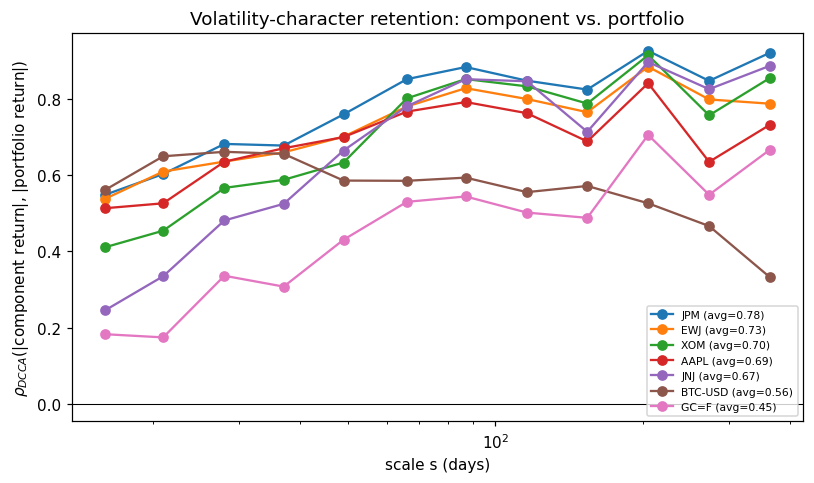

Volatility-character retention ranking (avg ρ_DCCA vs. portfolio volatility):
  1. JPM       (Financials)  avg ρ_DCCA = 0.782
  2. EWJ       (Intl ETF  )  avg ρ_DCCA = 0.733
  3. XOM       (Energy    )  avg ρ_DCCA = 0.705
  4. AAPL      (Tech      )  avg ρ_DCCA = 0.689
  5. JNJ       (Healthcare)  avg ρ_DCCA = 0.671
  6. BTC-USD   (Crypto    )  avg ρ_DCCA = 0.562
  7. GC=F      (Commodity )  avg ρ_DCCA = 0.452

-> 'JPM' contributes the most retained volatility character to this portfolio's own volatility dynamics.


In [7]:
vol_dcca_rows = []
for name in PORTFOLIO:
    rhos = [dcca_rho(vol[name], vol_p, s) for s in s_fixed]
    vol_dcca_rows.append((name, np.mean(rhos), rhos))

vol_dcca_rows.sort(key=lambda r: -r[1])

fig, ax = plt.subplots(figsize=(7.5,4.5))
for name, avg_rho, rhos in vol_dcca_rows:
    ax.plot(s_fixed, rhos, "o-", label=f"{name} (avg={avg_rho:.2f})")
ax.set_xscale("log"); ax.axhline(0, color="k", lw=0.7)
ax.set_xlabel("scale s (days)"); ax.set_ylabel(r"$\rho_{DCCA}$(|component return|, |portfolio return|)")
ax.set_title("Volatility-character retention: component vs. portfolio")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

print("Volatility-character retention ranking (avg ρ_DCCA vs. portfolio volatility):")
for rank, (name, avg_rho, _) in enumerate(vol_dcca_rows, 1):
    print(f"  {rank}. {name:9s} ({SECTOR[name]:10s})  avg ρ_DCCA = {avg_rho:.3f}")
print(f"\n-> '{vol_dcca_rows[0][0]}' contributes the most retained volatility character to this "
      f"portfolio's own volatility dynamics.")


**Rolling realized-volatility correlation** gives the same idea in a more familiar form —
does each asset's calm/stressed *regime* actually line up with the portfolio's, through time?
This is a second, independent cross-check on the ranking above (linear correlation of a smoothed
volatility proxy, rather than DCCA's scale-resolved detrended version); broad agreement between
the two rankings is reassuring, disagreement is itself informative about *which* scales the
retention happens at.


In [8]:
ROLL_VOL_WIN = 21
roll_vol = {name: pd.Series(vol[name]).rolling(ROLL_VOL_WIN).mean().values for name in PORTFOLIO}
roll_vol_p = pd.Series(vol_p).rolling(ROLL_VOL_WIN).mean().values

print(f"{'Ticker':9s}  corr(rolling {ROLL_VOL_WIN}d |r_i|, rolling |r_portfolio|)")
corr_rows = []
for name in PORTFOLIO:
    mask = ~(np.isnan(roll_vol[name]) | np.isnan(roll_vol_p))
    c = np.corrcoef(roll_vol[name][mask], roll_vol_p[mask])[0,1]
    corr_rows.append((name, c))
corr_rows.sort(key=lambda r: -r[1])
for name, c in corr_rows:
    print(f"{name:9s}  {c:.3f}")


Ticker     corr(rolling 21d |r_i|, rolling |r_portfolio|)
JPM        0.869
JNJ        0.818
XOM        0.790
AAPL       0.783
EWJ        0.707
BTC-USD    0.496
GC=F       0.422


**Reading Section 4 as a whole:** if the Volatility Diversification Ratio is comfortably
above 1 *and* no single component dominates the retention ranking, the portfolio's volatility
character is a genuine emergent blend — netting is doing real work. If the ratio is close to 1
and one asset (often the highest-volatility or most idiosyncratic holding — crypto and
commodities are common culprits) tops both the DCCA and rolling-correlation rankings by a wide
margin, that asset's volatility regime is effectively steering the whole book's risk profile,
regardless of how small its portfolio weight is — a fact a variance-weighted risk budget would
likely miss.


## 5. [New] Multifractal Diversification Ratio (MDR)

The classic **Diversification Ratio** (Choueifaty & Coignard, 2008) compares a portfolio's
volatility to the weighted-average volatility of its components — it only ever sees *linear*
(variance/covariance) risk. Here's a spectral-width analogue built from what Section 3 just
computed, for free:

$$\mathrm{MDR} = \frac{\sum_i w_i \, \Delta h_i}{\Delta h_{\text{portfolio}}}$$

where $\Delta h_i = h_i(q_{\min}) - h_i(q_{\max})$ is asset $i$'s multifractal spectrum width
(its tail/bulk scaling heterogeneity — a proxy for "how differently the asset's crashes behave
from its typical days").

- **MDR > 1**: diversification *narrows* the portfolio's spectrum relative to its components —
  the mix is genuinely smoothing out scale-dependent tail behavior, not just linear variance.
- **MDR < 1**: the portfolio's own multifractal width is *wider* than the weighted average of
  its parts — a "diversification illusion": components look individually well-behaved but their
  tail co-movements (Section 2's `ρ_DCCA`/`H_xy(q)`) combine into a *more* scale-heterogeneous,
  harder-to-model portfolio than any one holding alone. This is invisible to a covariance-matrix
  based diversification ratio, which would still report full credit for the same weights.


In [9]:
MDR = naive_width / width_p
print(f"Weighted-avg component width Δh̄ = {naive_width:.4f}")
print(f"Portfolio width Δh_p            = {width_p:.4f}")
print(f"Multifractal Diversification Ratio (MDR) = {MDR:.3f}")
print("MDR > 1 -> diversification narrows multifractal width (genuine benefit)."
      if MDR > 1 else
      "MDR < 1 -> portfolio is MORE scale-heterogeneous than its parts (diversification illusion).")


Weighted-avg component width Δh̄ = 0.2530
Portfolio width Δh_p            = 0.2405
Multifractal Diversification Ratio (MDR) = 1.052
MDR > 1 -> diversification narrows multifractal width (genuine benefit).


## 6. [New] Rolling MF-DCCA — cross-correlation as an early-warning signal

A single full-sample `ρ_DCCA(s)` averages over calm and crisis periods alike. Rolling it through
time — in the same spirit as the rolling `tc`/`Δα` panels in your LPPL notebook — turns MF-DCCA
into a **regime-change detector**: a sustained rise in short-horizon `ρ_DCCA` between assets that
are normally uncorrelated (e.g. equities vs. gold, or equities vs. BTC) is a scale-resolved
version of "correlations go to 1 in a crisis," visible *before* it shows up in a trailing
covariance matrix, because it isolates the DCCA covariance at a chosen scale rather than mixing
all scales into one number.


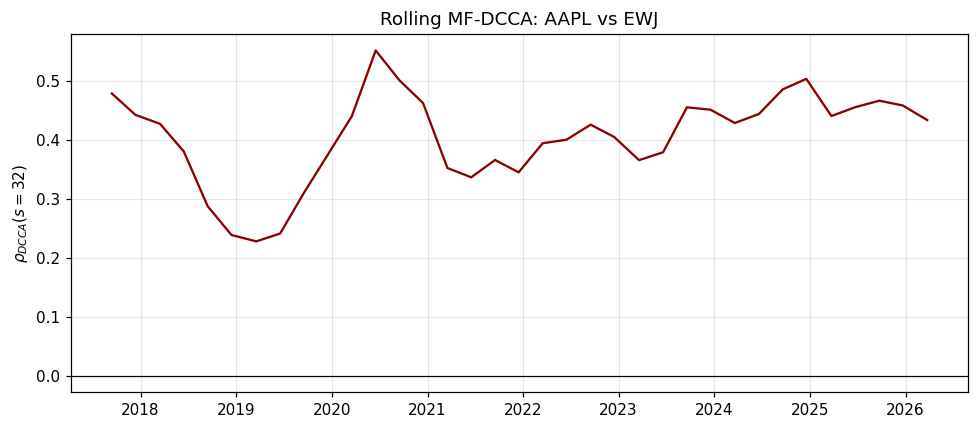

Spikes/plateaus above the historical baseline flag periods where this pair's short-horizon
co-movement decoupled from its long-run average — check them against known stress dates.


In [10]:
WINDOW, STEP, S_ROLL = 750, 63, 32   # ~3y window, ~1 quarter step, short (5-week) scale
pair_a, pair_b = PORTFOLIO[0], PORTFOLIO[-1]   # e.g. AAPL vs EWJ; change freely
ra, rb = returns[pair_a], returns[pair_b]

roll_dates, roll_rho = [], []
for end in range(WINDOW, N, STEP):
    start = end - WINDOW
    roll_rho.append(dcca_rho(ra[start:end], rb[start:end], S_ROLL))
    roll_dates.append(dates[end])

fig, ax = plt.subplots(figsize=(9,4))
ax.plot(roll_dates, roll_rho, color="darkred")
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel(fr"$\rho_{{DCCA}}(s={S_ROLL})$"); ax.set_title(f"Rolling MF-DCCA: {pair_a} vs {pair_b}")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
print("Spikes/plateaus above the historical baseline flag periods where this pair's short-horizon")
print("co-movement decoupled from its long-run average — check them against known stress dates.")


## 7. VaR vs. the homogeneous-scaling assumption

The $\sqrt{T}$ rule ($\mathrm{VaR}_T \approx \sqrt{T}\cdot\mathrm{VaR}_1$) is only correct if
returns are self-similar with Hurst exponent exactly 0.5 at every quantile. We test this directly
against the portfolio's actual horizon scaling and its MF-DFA tail exponent.


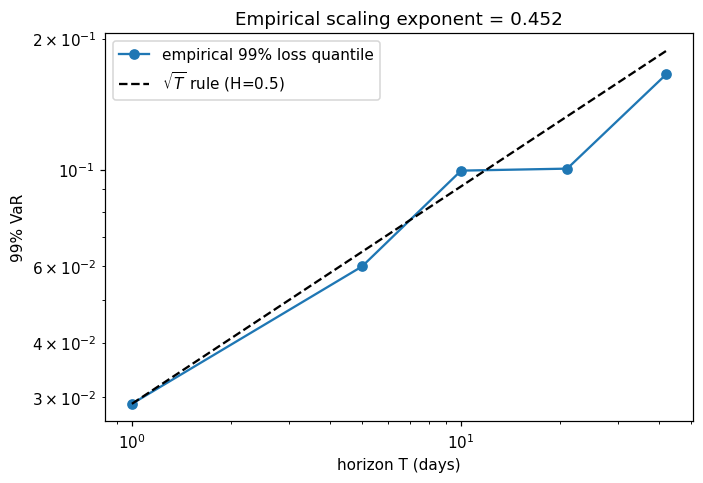

Empirical horizon-scaling exponent: 0.452
MF-DFA h(q=5) (tail):  0.386
MF-DFA h(q=2) (bulk):  0.531


In [11]:
horizons = [1, 5, 10, 21, 42]
alpha_level = 0.01
q99_by_h = []
for T in horizons:
    if T == 1:
        agg = port_ret
    else:
        usable = (len(port_ret)//T)*T
        agg = port_ret[:usable].reshape(-1, T).sum(axis=1)
    q99_by_h.append(-np.quantile(agg, alpha_level))
q99_by_h = np.array(q99_by_h)
empirical_exponent = np.polyfit(np.log(horizons), np.log(q99_by_h), 1)[0]

fig, ax = plt.subplots(figsize=(6.5,4.5))
ax.loglog(horizons, q99_by_h, "o-", label="empirical 99% loss quantile")
ax.loglog(horizons, q99_by_h[0]*np.sqrt(np.array(horizons)), "k--", label=r"$\sqrt{T}$ rule (H=0.5)")
ax.set_xlabel("horizon T (days)"); ax.set_ylabel("99% VaR")
ax.set_title(f"Empirical scaling exponent = {empirical_exponent:.3f}")
ax.legend(); plt.tight_layout(); plt.show()

print(f"Empirical horizon-scaling exponent: {empirical_exponent:.3f}")
print(f"MF-DFA h(q=5) (tail):  {hq_p[q_list==5][0]:.3f}")
print(f"MF-DFA h(q=2) (bulk):  {hq_p[q_list==2][0]:.3f}")


## 8. [New] Asymmetric MF-DFA — up-move vs. down-move persistence

Standard MF-DFA is blind to the *sign* of the local trend it detrends against — it can't tell you
whether crashes and rallies scale the same way. **Asymmetric MF-DFA** (Yuan et al., 2012) reruns
the fluctuation calculation separately over windows whose local trend is rising ($h^+(q)$) vs.
falling ($h^-(q)$). If $h^-(q) > h^+(q)$, downtrends are *more persistent* than uptrends — momentum
that continues once a decline starts — which is the multifractal fingerprint of the classic
**leverage effect**, and directly implies the left tail of the return distribution needs its own,
worse-scaling exponent than the right tail. A symmetric, single-`h(q)` risk model (which is what
both Gaussian VaR and even standard MF-DFA-based scaling implicitly use) misses this asymmetry
entirely.


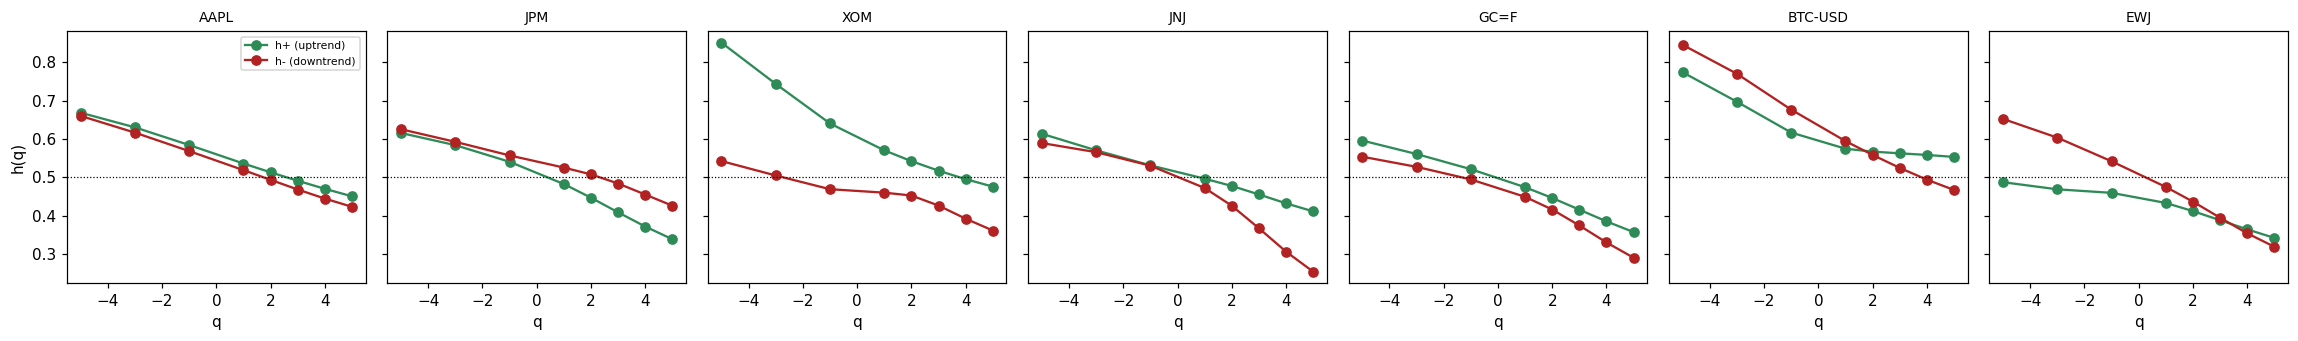

Ticker     h-(2)-h+(2)   interpretation
AAPL            -0.020   roughly symmetric
JPM              0.061   downtrends more persistent (leverage-effect signature)
XOM             -0.090   uptrends more persistent
JNJ             -0.052   uptrends more persistent
GC=F            -0.030   uptrends more persistent
BTC-USD         -0.009   roughly symmetric
EWJ              0.025   downtrends more persistent (leverage-effect signature)


In [12]:
hq_plus, hq_minus = {}, {}
for name, r in returns.items():
    _, hp = mfdfa(r, q_list, scales, sign_filter="+")
    _, hm = mfdfa(r, q_list, scales, sign_filter="-")
    hq_plus[name], hq_minus[name] = hp, hm

fig, axes = plt.subplots(1, len(PORTFOLIO), figsize=(3*len(PORTFOLIO), 3.2), sharey=True)
for ax, name in zip(axes, PORTFOLIO):
    ax.plot(q_list, hq_plus[name],  "o-", color="seagreen", label="h+ (uptrend)")
    ax.plot(q_list, hq_minus[name], "o-", color="firebrick", label="h- (downtrend)")
    ax.axhline(0.5, color="k", ls=":", lw=0.8)
    ax.set_title(name, fontsize=9); ax.set_xlabel("q")
axes[0].set_ylabel("h(q)"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

print(f"{'Ticker':9s} {'h-(2)-h+(2)':>12s}   interpretation")
for name in PORTFOLIO:
    gap = hq_minus[name][q_list==2][0] - hq_plus[name][q_list==2][0]
    tag = "downtrends more persistent (leverage-effect signature)" if gap > 0.02 else \
          ("uptrends more persistent" if gap < -0.02 else "roughly symmetric")
    print(f"{name:9s} {gap:12.3f}   {tag}")


## 9. [New] Multifractal-aware Expected Shortfall

Two independent ways to estimate how fat the tail really is:

- **Hill estimator** (classic EVT): fits a power-law tail directly to the largest losses,
  giving a tail index $\hat\alpha_{\text{Hill}}$ (smaller = fatter tail) and an EVT-style ES via
  $\mathrm{ES}_\alpha \approx \mathrm{VaR}_\alpha \cdot \frac{1}{1-1/\hat\alpha_{\text{Hill}}}$
  (valid for $\hat\alpha_{\text{Hill}} > 1$).
- **MF-DFA spectral width** $\Delta h$: doesn't estimate a tail index directly, but measures
  *how much the scaling law itself changes* between typical and extreme fluctuations.

These two are independent estimation approaches over the *same* return series. When they agree
(stable Hill estimate across a range of $k$, alongside a stable $\Delta h$ on a rolling basis),
a static EVT-based ES is trustworthy. When $\Delta h$ is drifting on a rolling basis even while a
single full-sample Hill estimate looks stable, that's a warning that the tail's scaling behavior
is non-stationary — an EVT parameter fit on the full history may already be stale for tomorrow's
risk, something a single Hill-plot alone would not show you.


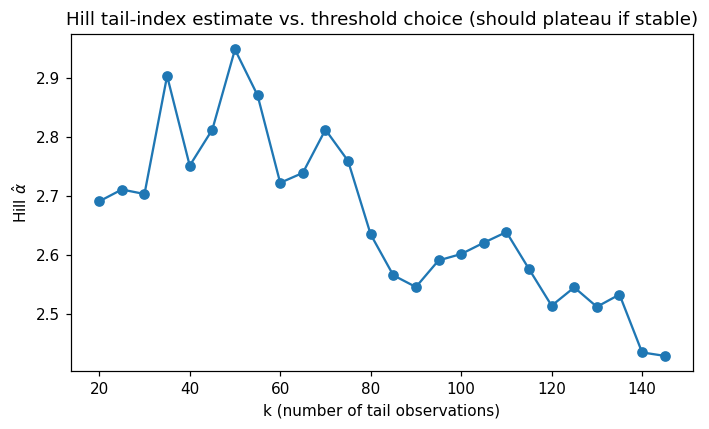

Hill tail index (k=60): alpha = 2.72
Historical VaR99 = 0.0289   Historical ES99 = 0.0454
EVT-implied ES99 = 0.0457   (uses only the tail index + VaR, not the raw ES average)


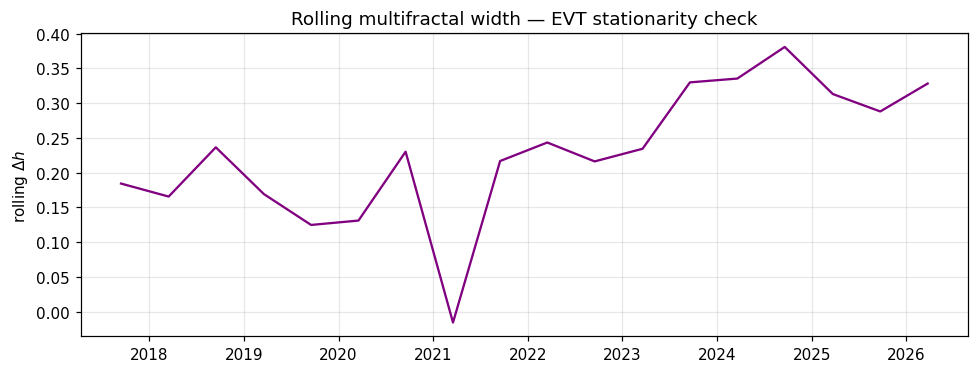

If this drifts a lot while the Hill plot above looks flat, treat the EVT-based ES as a
snapshot, not a constant — refit it on a rolling basis rather than once on full history.


In [13]:
losses = -port_ret
ks = np.arange(20, 150, 5)
hill_alphas = [hill_estimator(losses, k) for k in ks]

fig, ax = plt.subplots(figsize=(6.5,4))
ax.plot(ks, hill_alphas, "o-")
ax.set_xlabel("k (number of tail observations)"); ax.set_ylabel(r"Hill $\hat\alpha$")
ax.set_title("Hill tail-index estimate vs. threshold choice (should plateau if stable)")
plt.tight_layout(); plt.show()

k_use = 60
alpha_hill = hill_estimator(losses, k_use)
VaR99 = np.quantile(losses, 0.99)
ES99_hist = losses[losses >= VaR99].mean()
ES99_evt  = VaR99 / (1 - 1/alpha_hill) if alpha_hill > 1 else np.nan

print(f"Hill tail index (k={k_use}): alpha = {alpha_hill:.2f}")
print(f"Historical VaR99 = {VaR99:.4f}   Historical ES99 = {ES99_hist:.4f}")
print(f"EVT-implied ES99 = {ES99_evt:.4f}   (uses only the tail index + VaR, not the raw ES average)")

# rolling Δh (bulk-vs-tail spectral width) as a stationarity cross-check
WIN = 750
roll_width, roll_dates2 = [], []
for end in range(WIN, N, 126):
    seg = port_ret[end-WIN:end]
    _, hq_seg = mfdfa(seg, q_list, np.unique(np.geomspace(16, WIN//8, 10).astype(int)))
    roll_width.append(hq_seg[0]-hq_seg[-1])
    roll_dates2.append(dates[end])

fig, ax = plt.subplots(figsize=(9,3.5))
ax.plot(roll_dates2, roll_width, color="purple")
ax.set_ylabel(r"rolling $\Delta h$"); ax.set_title("Rolling multifractal width — EVT stationarity check")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
print("If this drifts a lot while the Hill plot above looks flat, treat the EVT-based ES as a")
print("snapshot, not a constant — refit it on a rolling basis rather than once on full history.")


## 10. Sub-additivity: a minimal counterexample

The theoretical failure of VaR's sub-additivity is easiest to see with a stylized pair of
jump-risk positions — the discrete analogue of the fat left tails multifractal cascades produce
continuously in the real data above.


In [14]:
rng = np.random.default_rng(3)
n_sims = 200_000
p_jump = 0.008
loss_A = np.where(rng.random(n_sims) < p_jump, rng.uniform(8, 12, n_sims), rng.normal(0, 1, n_sims))
loss_B = np.where(rng.random(n_sims) < p_jump, rng.uniform(8, 12, n_sims), rng.normal(0, 1, n_sims))
loss_AB = loss_A + loss_B

alpha = 0.99
VaR_A, VaR_B, VaR_AB = (np.quantile(l, alpha) for l in (loss_A, loss_B, loss_AB))
print(f"VaR99(A)={VaR_A:.3f}  VaR99(B)={VaR_B:.3f}  sum={VaR_A+VaR_B:.3f}  VaR99(A+B)={VaR_AB:.3f}")
print(f"Sub-additive? {VaR_AB <= VaR_A + VaR_B}")

ES_A  = loss_A[loss_A   >= VaR_A ].mean()
ES_B  = loss_B[loss_B   >= VaR_B ].mean()
ES_AB = loss_AB[loss_AB >= VaR_AB].mean()
print(f"\nES99(A)+ES99(B)={ES_A+ES_B:.3f}   ES99(A+B)={ES_AB:.3f}   Sub-additive (ES)? {ES_AB <= ES_A+ES_B}")


VaR99(A)=2.886  VaR99(B)=2.891  sum=5.776  VaR99(A+B)=9.475
Sub-additive? False

ES99(A)+ES99(B)=17.457   ES99(A+B)=11.058   Sub-additive (ES)? True


## 11. Takeaways

| Axiom | VaR | Multifractal angle |
|---|---|---|
| Monotonicity | holds | unaffected by scaling behavior |
| Translation invariance | holds | unaffected |
| Positive homogeneity | holds for fixed λ, fixed horizon | the $\sqrt{T}$ horizon-scaling shortcut assumes monofractal $h(q)\equiv0.5$; Section 6 tests this directly against the real portfolio |
| Sub-additivity | can fail | Section 9; fat/jump/multifractal tails are exactly where this bites |

**New tools added here, and how to read them:**
- **Component-vs-portfolio volatility retention** (Section 4): separates real diversification
  (netted `v_p` vs. the no-netting `v_p^{naive}` benchmark) from which single asset's volatility
  regime the portfolio ends up tracking most closely — a risk-attribution question a variance
  covariance matrix alone doesn't answer.
- **MDR** (Section 5): one number, computed for free from spectra you already have, that tells
  you whether a given set of portfolio weights is taming or amplifying scale-dependent tail risk
  — something a variance-based diversification ratio cannot see.
- **Rolling MF-DCCA** (Section 5): a scale-resolved, time-resolved cross-correlation monitor —
  a genuinely different early-warning signal from a rolling Pearson correlation, because it can
  isolate co-movement at the specific horizon your risk limits actually care about.
- **Asymmetric MF-DFA** (Section 7): tests whether downside and upside moves are governed by the
  same scaling law at all — if not, any single-`h(q)` or Gaussian VaR model is missing a
  first-order feature of the return process, not a second-order refinement.
- **Hill-vs-Δh cross-check** (Section 8): treats a static EVT tail-index ES the way it should be
  treated — as an estimate that can go stale — and gives a rolling multifractal diagnostic for
  *when* to worry that it has.

Together these turn "the market is multifractal" from a stylized fact into a set of concrete,
portfolio-level checks on the assumptions VaR (and even naive covariance-based diversification)
are quietly making.
